In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings("ignore")
%matplotlib inline

In [5]:
dataset = pd.read_csv("train-data.csv")
print(dataset.shape)
dataset.info()


(6019, 14)
<class 'pandas.DataFrame'>
RangeIndex: 6019 entries, 0 to 6018
Data columns (total 14 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Unnamed: 0         6019 non-null   int64  
 1   Name               6019 non-null   str    
 2   Location           6019 non-null   str    
 3   Year               6019 non-null   int64  
 4   Kilometers_Driven  6019 non-null   int64  
 5   Fuel_Type          6019 non-null   str    
 6   Transmission       6019 non-null   str    
 7   Owner_Type         6019 non-null   str    
 8   Mileage            6017 non-null   str    
 9   Engine             5983 non-null   str    
 10  Power              5983 non-null   str    
 11  Seats              5977 non-null   float64
 12  New_Price          824 non-null    str    
 13  Price              6019 non-null   float64
dtypes: float64(2), int64(3), str(9)
memory usage: 658.5 KB


In [6]:
dataset.head()

,Unnamed: 0,Name,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,New_Price,Price
0,0,Maruti Wagon R LXI CNG,Mumbai,2010,72000,CNG,Manual,First,26.6 km/kg,998 CC,58.16 bhp,5.0,NaN,1.75
1,1,Hyundai Creta 1.6 CRDi SX Option,Pune,2015,41000,Diesel,Manual,First,19.67 kmpl,1582 CC,126.2 bhp,5.0,NaN,12.50
2,2,Honda Jazz V,Chennai,2011,46000,Petrol,Manual,First,18.2 kmpl,1199 CC,88.7 bhp,5.0,8.61 Lakh,4.50
3,3,Maruti Ertiga VDI,Chennai,2012,87000,Diesel,Manual,First,20.77 kmpl,1248 CC,88.76 bhp,7.0,NaN,6.00
4,4,Audi A4 New 2.0 TDI Multitronic,Coimbatore,2013,40670,Diesel,Automatic,Second,15.2 kmpl,1968 CC,140.8 bhp,5.0,NaN,17.74


In [7]:
#  Cleaning
n_before = len(dataset)
dataset = dataset.drop(['Unnamed: 0', 'New_Price'], axis=1)

for col in ['Mileage', 'Engine', 'Power']:
    dataset[col] = dataset[col].str.extract(r'([\d.]+)')[0].astype(float)

dataset = dataset.dropna()
dataset = dataset[dataset['Mileage'] > 0]

dataset = dataset[(dataset['Kilometers_Driven'] < 1_000_000) & (dataset['Price'] < 120)]

dataset['Engine'] = dataset['Engine'].astype(int)

dataset['Brand Name'] = dataset['Name'].str.split().str[0].replace({'Land': 'Land Rover', 'ISUZU': 'Isuzu'})
dataset = dataset.drop('Name', axis=1)

dataset = dataset.drop_duplicates().reset_index(drop=True)
print(f"Rows: {n_before} -> {len(dataset)}")
print("Missing values:", dataset.isnull().sum().sum(), "| Duplicates:", dataset.duplicated().sum())
dataset.head()

Rows: 6019 -> 5839
Missing values: 0 | Duplicates: 0


,Location,Year,Kilometers_Driven,Fuel_Type,Transmission,Owner_Type,Mileage,Engine,Power,Seats,Price,Brand Name
0,Mumbai,2010,72000,CNG,Manual,First,26.60,998,58.16,5.0,1.75,Maruti
1,Pune,2015,41000,Diesel,Manual,First,19.67,1582,126.20,5.0,12.50,Hyundai
2,Chennai,2011,46000,Petrol,Manual,First,18.20,1199,88.70,5.0,4.50,Honda
3,Chennai,2012,87000,Diesel,Manual,First,20.77,1248,88.76,7.0,6.00,Maruti
4,Coimbatore,2013,40670,Diesel,Automatic,Second,15.20,1968,140.80,5.0,17.74,Audi


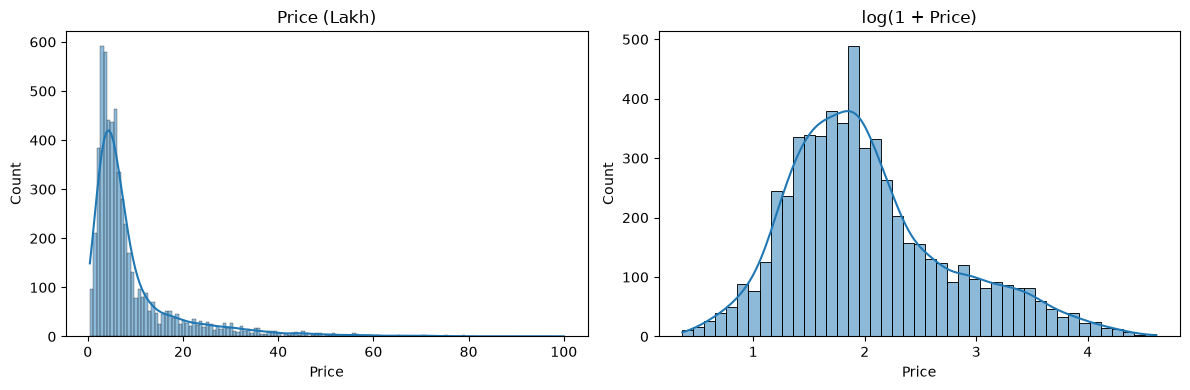

In [8]:
# Price distribution (raw vs log)
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(dataset['Price'], kde=True, ax=axes[0])
axes[0].set_title('Price (Lakh)')
sns.histplot(np.log1p(dataset['Price']), kde=True, ax=axes[1])
axes[1].set_title('log(1 + Price)')
plt.tight_layout()
plt.show()

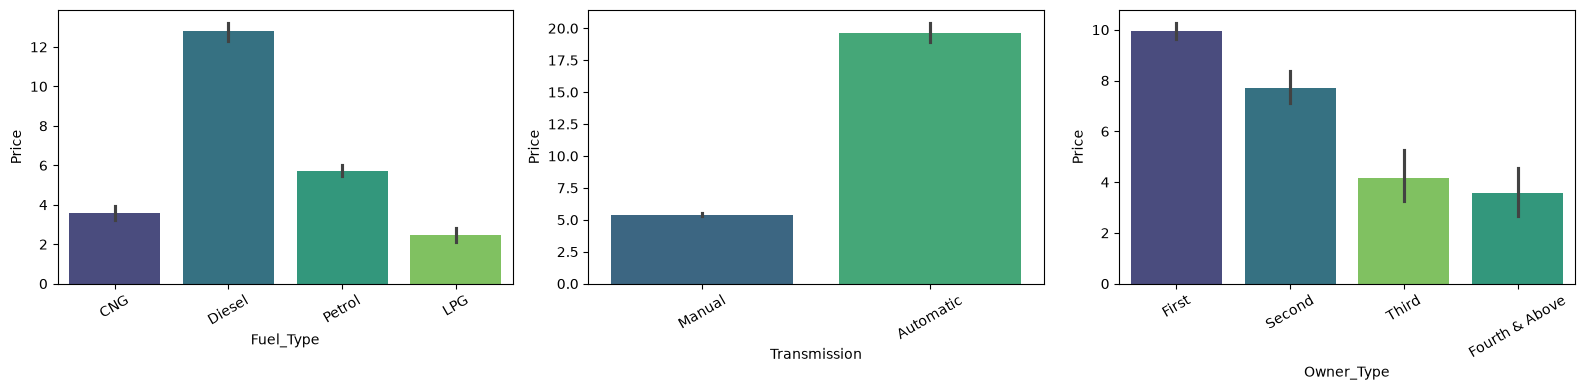

Fuel_Type
Diesel    3131
Petrol    2643
CNG         55
LPG         10
Name: count, dtype: int64


In [9]:
# Categorical features vs Price
owner_order = ['First', 'Second', 'Third', 'Fourth & Above']
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.barplot(data=dataset, x='Fuel_Type', y='Price', hue='Fuel_Type', palette='viridis', legend=False, ax=axes[0])
sns.barplot(data=dataset, x='Transmission', y='Price', hue='Transmission', palette='viridis', legend=False, ax=axes[1])
sns.barplot(data=dataset, x='Owner_Type', y='Price', order=owner_order, hue='Owner_Type', palette='viridis', legend=False, ax=axes[2])
for ax in axes:
    ax.tick_params(axis='x', rotation=30)
plt.tight_layout()
plt.show()

print(dataset['Fuel_Type'].value_counts())

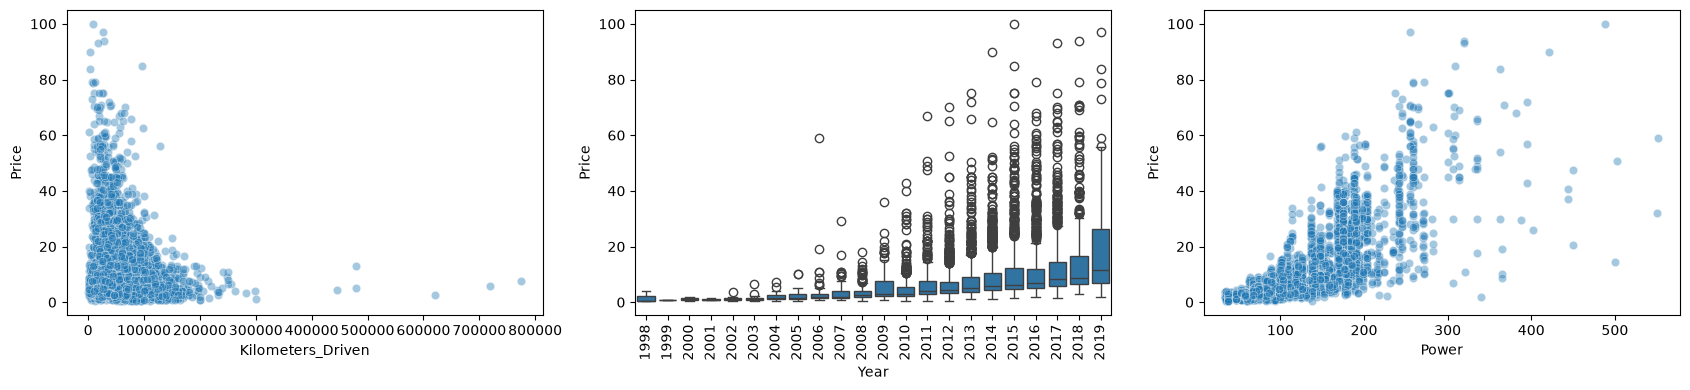

In [10]:
# Numeric features vs Price
fig, axes = plt.subplots(1, 3, figsize=(17, 4))
sns.scatterplot(data=dataset, x='Kilometers_Driven', y='Price', alpha=0.4, ax=axes[0])
sns.boxplot(data=dataset, x='Year', y='Price', ax=axes[1])
axes[1].tick_params(axis='x', rotation=90)
sns.scatterplot(data=dataset, x='Power', y='Price', alpha=0.4, ax=axes[2])
plt.tight_layout()
plt.show()

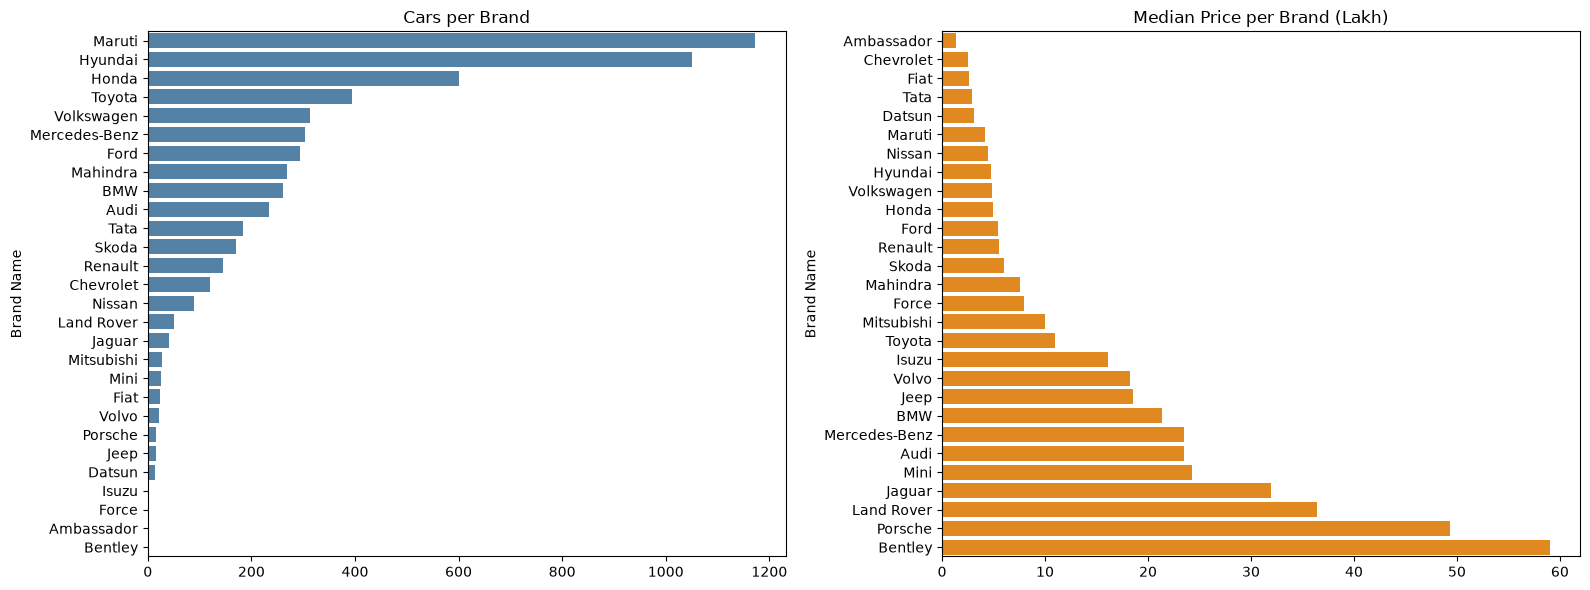

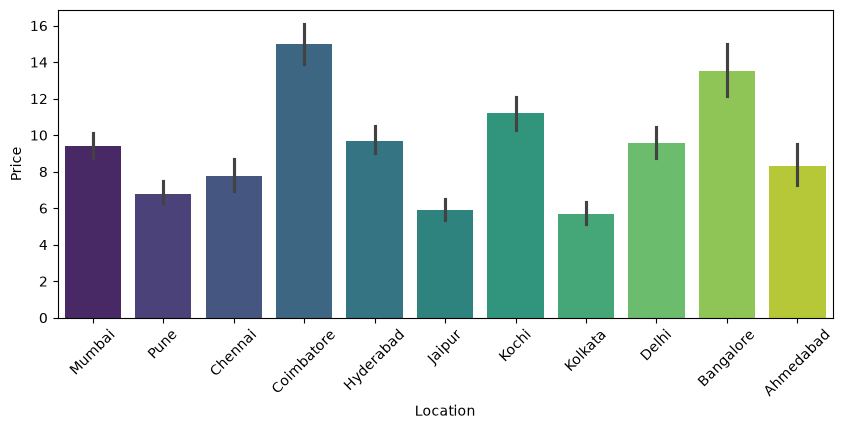

In [11]:
# Brand & Location
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
brand_counts = dataset['Brand Name'].value_counts()
sns.barplot(x=brand_counts.values, y=brand_counts.index, ax=axes[0], color='steelblue')
axes[0].set_title('Cars per Brand')
brand_price = dataset.groupby('Brand Name')['Price'].median().sort_values()
sns.barplot(x=brand_price.values, y=brand_price.index, ax=axes[1], color='darkorange')
axes[1].set_title('Median Price per Brand (Lakh)')
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 4))
sns.barplot(data=dataset, x='Location', y='Price', hue='Location', palette='viridis', legend=False)
plt.xticks(rotation=45)
plt.show()

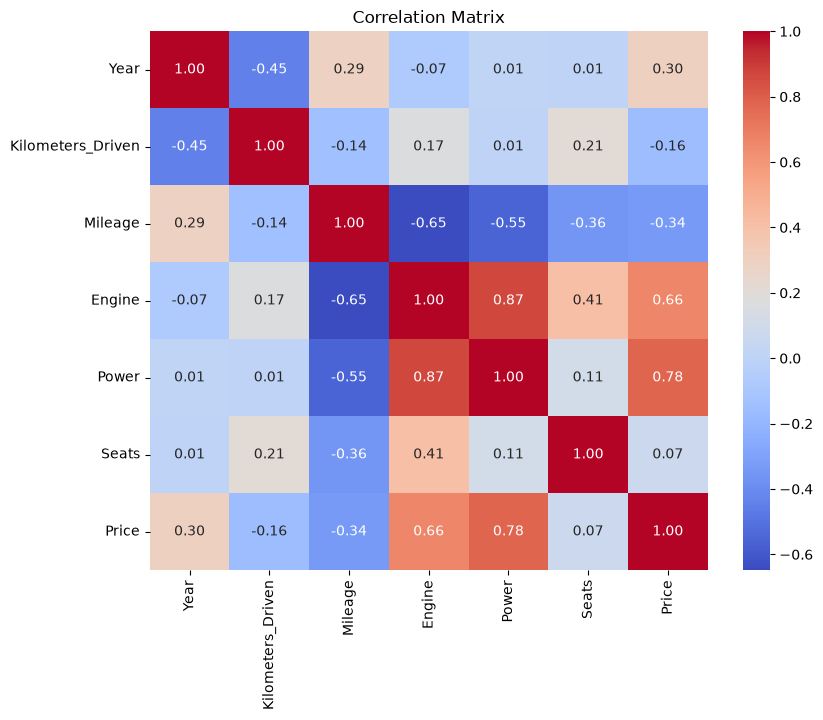

In [12]:
plt.figure(figsize=(9, 7))
sns.heatmap(dataset.corr(numeric_only=True), annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Correlation Matrix')
plt.show()

In [13]:
dataset.to_csv("cleaned_train_data.csv", index=False)
print("Saved cleaned_train_data.csv", dataset.shape)

Saved cleaned_train_data.csv (5839, 12)
